# Wind-Inflow Sensitivity of NREL 5 MW Turbine Loads Near Rated Wind Speed

__Amy N. Robertson, Kelsey Shaler, Latha Sethuraman and Jason Jonkman__, National Renewable Energy Laboratory, Golden, Colorado (the study: inflow model, parameters and ranges)

__Paul G. Constantine__ (the OpenFAST runs of this data set, 2026)

Notebook: P. G. Constantine with Claude (Anthropic), 2026

<br>

Robertson et al. [[1]](https://doi.org/10.5194/wes-4-479-2019) asked which wind-inflow parameters most affect the power, ultimate loads and fatigue loads of the NREL 5 MW reference turbine in normal operation. They varied 18 parameters of a Veers-type turbulence model (shear, veer, three standard deviations, three integral scales, seven coherence parameters and three Reynolds stresses) over ranges drawn from measurements at many sites, simulated the turbine with TurbSim and OpenFAST in three wind-speed bins, and screened the parameters with elementary effects. **This data set is new OpenFAST runs that use the paper's model, not a reproduction of its simulations.** The paper defines the model here: the turbine, the inflow model, the 18 inputs and their near-rated ranges (hub-height mean wind speed 12 m/s), and the quantities of interest. The runs were sized to the computing available for them, a limited number of cloud machine-hours, and their simulation settings differ from the paper's (design, wind grid, transient, tower aerodynamics, definition of the ultimate bending moments; see "Settings: the paper and this data set" at the end): 300 sets of the 18 inputs drawn uniformly from the near-rated ranges, each simulated with the same 30 turbulence seeds, 9000 ten-minute simulations in all. The paper's authors found their large volume of simulation output impractical to save and to share publicly, so its runs are not available [[1, p. 504]](https://doi.org/10.5194/wes-4-479-2019). We ask whether the loads have a low-dimensional active subspace in the 18 inputs and which inputs make it up. The results stand on their own and may or may not agree with the paper's conclusions; a short section at the end relates them. The notebook runs in Python 3.11 with numpy, matplotlib and [active_subspaces](https://github.com/paulcon/active_subspaces).

In [1]:
%matplotlib inline
import csv
import json
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac

SEED = 479                        # the only seed in this notebook: bootstrap, subsamples and cross-validation folds
rng = np.random.default_rng(SEED)
t_start = time.perf_counter()
# OLS and the global quadratic (qphd) estimators warn that their Stein-lemma justification assumes Gaussian
# inputs; here they are used as fits (see "Estimating the subspace without gradients"), so the warning is muted.
warnings.filterwarnings('ignore', category=ac.ValidityWarning)

### Summary

In 9000 new OpenFAST runs of the paper's near-rated case (300 uniform draws of the 18 inflow inputs on the paper's Table 3 ranges, 30 common seeds each; 284 sets with all seeds complete), the ultimate and fatigue loads of the NREL 5 MW turbine have a leading active direction, led by the along-wind turbulence $\sigma_u$. By the largest of the first three eigenvalue gaps, 21 of the 30 quantities of interest are one-dimensional and 9 two-dimensional, among them the blade-root out-of-plane fatigue load; 2 of the 9 (`RotTorq_DEL`, `YawBrMxp_DEL`) have no well-determined subspace, because their seed noise is too large (as for two one-dimensional fatigue loads). For the out-of-plane blade-root bending moment, the ultimate load's direction is $\sigma_u$ $+0.845$, shear exponent $\alpha$ $+0.373$, coherence decrement $a_u$ $-0.195$ and offset $b_u$ $-0.164$, and a quadratic in that one variable has cross-validated $R^2 = 0.857$; for the tower-base fore-aft moment it is $\sigma_u$ $+0.824$, integral scale $L_u$ $-0.353$, $a_u$ $-0.236$ ($R^2 = 0.825$). The fatigue loads (DELs) have similar first directions. A second direction ($\alpha$ for the blade root, $L_u$ for the tower base) raises the cross-validated $R^2$ of these four loads to 0.870–0.902 (for the blade-root DEL from 0.835 to 0.893, where the eigenvalue gap after the second eigenvalue is the larger), but it is less well determined, especially for the tower base. By activity score, $\sigma_u$ is the most important input for 25 of the 29 loads; the exceptions are the low-speed-shaft fatigue loads, which are smallest at an intermediate shear exponent and grow on both sides of it, and two blade-root fatigue loads the inflow hardly affects. The paper, whose simulations differ from these in several settings and pool three wind-speed bins, also finds $\sigma_u$ the most influential inflow parameter, but ranks the shear exponent $\alpha$ higher than this data set does; a wider shear range below rated, in the paper's other bins, is one possible reason. Caveats: the realized hub $\sigma_u$ is about 7 % (median) below its target, more where $L_u$ is large, consistent in part with the 660 s record not holding the spectrum's lowest frequencies; with the realized $\sigma_u$ in place of the target, the weight of $L_u$ on the tower-base loads shrinks (ultimate $-0.353$ to $-0.286$), so part of that weight may be this record-length effect. In 86 sets the Reynolds-stress inputs exceed what the standard deviations allow, so TurbSim inflates $\sigma_v$ and $\sigma_w$; 38 sets needed a modification of the coherence matrix in a patched TurbSim; and 16 sets had failed runs. Leaving out the failed runs' sets, the modified sets or the infeasible sets does not change the first direction appreciably. The ultimate bending moments are single components, not the paper's vector sums; whether the vector sums would change the directions cannot be tested from the stored files.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend and a function of $\mathbf y$ can stand in for $f$. The diagonal of $\mathbf C$, the *activity scores* with $n = m$, are mean squared partial derivatives, a global sensitivity measure [[3]](https://doi.org/10.1016/j.ress.2017.01.013) related to the elementary effects the paper uses, which are finite-difference derivatives. See P. G. Constantine, *Active Subspaces* [[2]](https://doi.org/10.1137/1.9781611973860).

Here the quantities of interest are seed averages of turbulent simulations with no gradients, so $\mathbf C$ is estimated from fits to the 284 usable sets (see "Estimating the subspace without gradients").

### The model

**Turbine and codes.** The turbine is the NREL 5 MW reference turbine [[5]](https://doi.org/10.2172/947422) (three-bladed, upwind, variable speed, collective pitch; hub height 90 m, rotor diameter 126 m) [[1, p. 480]](https://doi.org/10.5194/wes-4-479-2019). The runs use OpenFAST v3.5.5 [[4]](https://github.com/OpenFAST/openfast/tree/v3.5.5) with the land-based regression-test case `5MW_Land_DLL_WTurb` of that version (ElastoDyn; AeroDyn 15 with blade-element momentum and Beddoes-Leishman unsteady aerodynamics; ServoDyn with the baseline controller; InflowWind reading a TurbSim full-field file). Each run simulates 660 s; the first 60 s are dropped, and the statistics use the last 600 s. The paper simulated 10 min after a 30 s transient [[1, p. 480]](https://doi.org/10.5194/wes-4-479-2019).

**Inflow.** TurbSim (the version in OpenFAST v3.5.5) generates the turbulent wind on a 15 × 15 grid, 145 m square, at 0.05 s, with the hub-height mean wind speed $V_{hub} = 12$ m/s of the paper's near-rated bin [[1, p. 480]](https://doi.org/10.5194/wes-4-479-2019). The 18 inputs enter as follows.

* *Mean wind profile*: a power law with exponent $\alpha$ for the speed, and a linear wind-direction change totalling $\beta$ across the rotor, centred on the hub and following the right-hand rule about the vertical axis [[1, p. 485]](https://doi.org/10.5194/wes-4-479-2019). It is given to TurbSim as a user profile; the direction is held at its rotor-edge values above and below the rotor (this data set's choice). TurbSim adds the profile's direction to its horizontal flow angle, which its code treats as counter-clockwise seen from above (`getDirectionProfile` in `modules/turbsim/src/Profiles.f90`; DATA.md gives the lines), so a positive $\beta$ here turns the wind by the right-hand rule about the upward vertical, as in the paper.
* *Velocity spectrum*: the Kaimal spectrum of each component $q = u, v, w$, Eq. 7 of the paper [[1, p. 485]](https://doi.org/10.5194/wes-4-479-2019),
$$\frac{f\,S_q(f)}{\sigma_q^2} = \frac{4 f L_q/V_{hub}}{(1 + 6 f L_1/V_{hub})^{5/3}},$$
as printed, with $L_1$ in the denominator. The text below the equation defines $L_q$ as the integral scale parameter of component $q$, and the paper gives a separate scale for each component ($L_u$, $L_v$, $L_w$, same page), so we read $L_1$ as a misprint for $L_q$; the runs use $L_q$. The spectra are given to TurbSim as user-defined spectra on 400 log-spaced frequencies from $10^{-4}$ to 10 Hz (this data set's choice).
* *Spatial coherence*: the general coherence model, Eq. 8 [[1, p. 485]](https://doi.org/10.5194/wes-4-479-2019),
$$\mathrm{Coh}_{q,f} = \exp\left(-a_q\left(\frac{d}{z_m}\right)^{\gamma}\sqrt{\left(\frac{f d}{V_{hub}}\right)^2 + \left(b_q d\right)^2}\right),$$
with $d$ the distance between two points and $z_m$ their mean height. The paper notes that the use of $V_{hub}$ was a modification of TurbSim at the time [[1, p. 485]](https://doi.org/10.5194/wes-4-479-2019); TurbSim in OpenFAST v3.5.5 uses $V_{hub}$ without modification (`modules/turbsim/src/TSsubs.f90`, `CalcFourierCoeffs_General`, where the earlier two-point mean speed is commented out; DATA.md gives the lines).
* *Component correlation*: the hub Reynolds stresses $PC_{uw}$, $PC_{uv}$, $PC_{vw}$. The paper describes TurbSim as forming the $v$ and $w$ series from linear combinations of the three independent component series to reach these Reynolds stresses at the hub, so that the $v$ and $w$ spectra are somewhat affected [[1, p. 485]](https://doi.org/10.5194/wes-4-479-2019). In the v3.5.5 code (`TimeSeriesScaling_ReynoldsStress` in the same file), the multiples are computed from the hub point's series, applied at every grid point and clipped to $[-1, 1]$, so a stress the variances cannot carry is not reached.

**A change to TurbSim.** With $\gamma > 0$ the general coherence matrix need not be positive definite, and unmodified TurbSim then stops with a Cholesky error. For these runs TurbSim was patched (`patch_turbsim.py`): at a frequency where the factorization fails, it is retried with the off-diagonal coherences divided by $1 + \epsilon$, $\epsilon = 10^{-5}, 10^{-4}, \dots, 10$, and the largest $\epsilon$ used is recorded for each run. The paper does not say how non-positive-definite coherence matrices were handled.

### The inputs

The 18 inputs and their near-rated ranges are those of Table 3 of the paper [[1, p. 486]](https://doi.org/10.5194/wes-4-479-2019). Table 2 (p. 484) lists them; its header misprints "Mean wind profile" as "Mean mind profile" and labels the shear exponent $\alpha$ "Shear ($\sigma$)". The paper takes each range from published measurements at many sites (Sect. 4.1.2 and Table 3) and treats the parameters as independent, accepting that some combinations are not physical [[1, pp. 485-487]](https://doi.org/10.5194/wes-4-479-2019). Here they are independent and uniform on those ranges (this data set's choice; the paper uses ranges, not distributions). The "IEC nom." column is the IEC Class B nominal value Table 3 gives for the near-rated bin, where it gives one.

In [2]:
params = json.load(open('params.json'))
names = [p['name'] for p in params]
lower = np.array([p['low'] for p in params], float)
upper = np.array([p['high'] for p in params], float)
units = [None, 'deg', 'm', 'm', 'm', 'm/s', 'm/s', 'm/s', None, None, None, '1/m', '1/m', '1/m', None,
         'm^2/s^2', 'm^2/s^2', 'm^2/s^2']
labels = [r'$\alpha$', r'$\beta$', r'$L_u$', r'$L_v$', r'$L_w$', r'$\sigma_u$', r'$\sigma_v$', r'$\sigma_w$',
          r'$a_u$', r'$a_v$', r'$a_w$', r'$b_u$', r'$b_v$', r'$b_w$', r'$\gamma$', r'$PC_{uw}$', r'$PC_{uv}$', r'$PC_{vw}$']
desc = ['shear (power-law) exponent', 'total veer across the rotor', 'integral scale parameter, u',
        'integral scale parameter, v', 'integral scale parameter, w', 'standard deviation, u', 'standard deviation, v',
        'standard deviation, w', 'coherence decrement, u', 'coherence decrement, v', 'coherence decrement, w',
        'coherence offset, u', 'coherence offset, v', 'coherence offset, w', 'coherence exponent',
        "Reynolds stress u'w'", "Reynolds stress u'v'", "Reynolds stress v'w'"]
nominal = {'alpha': 0.2, 'beta': 0, 'Lu': 340, 'Lv': 110, 'Lw': 28, 'sigu': 2.0, 'sigv': 1.6, 'sigw': 1.0,
           'au': 12, 'bu': 3.5e-4, 'gamma': 0}      # Table 3, near-rated "Nom." row (IEC Class B)
space = ac.Uniform(lower, upper, names=names, units=units)
m = len(names)
print(f"{'input':6s} {'units':8s} {'min':>8s} {'max':>8s} {'IEC nom.':>8s}  description")
for j, n in enumerate(names):
    print(f"{n:6s} {units[j] or '-':8s} {lower[j]:8.3g} {upper[j]:8.3g} {nominal.get(n, float('nan')):8.3g}  {desc[j]}")

input  units         min      max IEC nom.  description
alpha  -            -0.4      0.9      0.2  shear (power-law) exponent
beta   deg           -10       50        0  total veer across the rotor
Lu     m               8  1.4e+03      340  integral scale parameter, u
Lv     m               2  1.3e+03      110  integral scale parameter, v
Lw     m               2      450       28  integral scale parameter, w
sigu   m/s           0.2      7.3        2  standard deviation, u
sigv   m/s          0.05      8.1      1.6  standard deviation, v
sigw   m/s          0.05      4.3        1  standard deviation, w
au     -             1.5       26       12  coherence decrement, u
av     -             1.7       18      nan  coherence decrement, v
aw     -               2       17      nan  coherence decrement, w
bu     1/m             0     0.08  0.00035  coherence offset, u
bv     1/m             0    0.003      nan  coherence offset, v
bw     1/m             0    0.006      nan  coherence offs

### Quantities of interest

The paper's quantities of interest are the blade-root, low-speed-shaft, tower-top and tower-base moments, the blade-tip out-of-plane deflection and the electrical power (Table 1, p. 482). For the OpenFAST output channels behind them, the runs store, per run, the maximum of $|x(t)|$ over the 600 s and, for the moments, the rainflow damage sum $\sum_i n_i S_i^m$. Per set of inputs:

* the **ultimate load** is the mean over the $S$ seeds of the maximum absolute value, the paper's Eq. 5 [[1, p. 483]](https://doi.org/10.5194/wes-4-479-2019);
* the **damage-equivalent load** (DEL) is aggregated over the seeds, $\mathrm{DEL} = \bigl(\sum_{\text{seeds}}\sum_i n_i S_i^m / (S \cdot 600\ \mathrm{s} \cdot 1\ \mathrm{Hz})\bigr)^{1/m}$, with ranges about a zero fixed mean and no Goodman correction, as in the paper [[1, p. 483]](https://doi.org/10.5194/wes-4-479-2019). The paper used MLife and does not give the S-N exponents; here $m = 10$ for the blade-root moments and $m = 4$ for the others (this data set's choice).

One difference matters for the comparison: for the bending moments, the paper's ultimate load is the largest *vector sum* of the first two components (e.g. out-of-plane and in-plane at the blade root) [[1, p. 481]](https://doi.org/10.5194/wes-4-479-2019). The runs kept each channel's maximum separately, so the vector sums cannot be formed, and the ultimate loads here are per component. The low-speed-shaft channels `LSSGagMya` and `LSSGagMza` are bending moments at the shaft strain gauge, `ShftGagL` = 1.912 m from the rotor apex in the ElastoDyn input of the regression-test case.

In [3]:
# OpenFAST channels behind the paper's quantities of interest (Table 1, p. 482); units from the OpenFAST output
QOI = {   # channel: (description, units)
    'RootMyc1': ('blade-root out-of-plane bending, blade 1', 'kN m'),
    'RootMxc1': ('blade-root in-plane bending, blade 1', 'kN m'),
    'RootMzc1': ('blade-root pitching moment, blade 1', 'kN m'),
    'RootMyc2': ('blade-root out-of-plane bending, blade 2', 'kN m'),
    'RootMyc3': ('blade-root out-of-plane bending, blade 3', 'kN m'),
    'LSSGagMya': ('low-speed-shaft bending at the strain gauge (LSSGagMya)', 'kN m'),
    'LSSGagMza': ('low-speed-shaft bending at the strain gauge (LSSGagMza)', 'kN m'),
    'RotTorq': ('rotor (shaft) torque', 'kN m'),
    'YawBrMyp': ('tower-top fore-aft bending', 'kN m'),
    'YawBrMxp': ('tower-top side-side bending', 'kN m'),
    'YawBrMzp': ('tower-top yaw moment', 'kN m'),
    'TwrBsMyt': ('tower-base fore-aft bending', 'kN m'),
    'TwrBsMxt': ('tower-base side-side bending', 'kN m'),
    'OoPDefl1': ('blade-tip out-of-plane deflection, blade 1', 'm'),
    'OoPDefl2': ('blade-tip out-of-plane deflection, blade 2', 'm'),
    'OoPDefl3': ('blade-tip out-of-plane deflection, blade 3', 'm'),
}
SN = {c: (10 if c.startswith('Root') else 4) for c in QOI if not c.startswith('OoP')}   # S-N exponent of the DEL
print(f"{'column':15s} {'units':5s} {'m':>3s}  description")
for c, (d, u) in QOI.items():
    print(f'{c + "_ult":15s} {u:5s} {"":>3s}  ultimate: {d}')
for c, mm in SN.items():
    print(f'{c + "_DEL":15s} {QOI[c][1]:5s} {mm:3d}  damage-equivalent load: {QOI[c][0]}')
print(f"{'GenPwr_mean':15s} {'kW':5s} {'':>3s}  electrical power, mean over 600 s and the seeds")

column          units   m  description
RootMyc1_ult    kN m       ultimate: blade-root out-of-plane bending, blade 1
RootMxc1_ult    kN m       ultimate: blade-root in-plane bending, blade 1
RootMzc1_ult    kN m       ultimate: blade-root pitching moment, blade 1
RootMyc2_ult    kN m       ultimate: blade-root out-of-plane bending, blade 2
RootMyc3_ult    kN m       ultimate: blade-root out-of-plane bending, blade 3
LSSGagMya_ult   kN m       ultimate: low-speed-shaft bending at the strain gauge (LSSGagMya)
LSSGagMza_ult   kN m       ultimate: low-speed-shaft bending at the strain gauge (LSSGagMza)
RotTorq_ult     kN m       ultimate: rotor (shaft) torque
YawBrMyp_ult    kN m       ultimate: tower-top fore-aft bending
YawBrMxp_ult    kN m       ultimate: tower-top side-side bending
YawBrMzp_ult    kN m       ultimate: tower-top yaw moment
TwrBsMyt_ult    kN m       ultimate: tower-base fore-aft bending
TwrBsMxt_ult    kN m       ultimate: tower-base side-side bending
OoPDefl1_ult    m 

### Load data, with checks

`sets.csv` has one row per set of inputs (the inputs, the number of seeds that ran, and the per-set quantities of interest); `runs.csv` has one row per run (status, TurbSim diagnostics, the per-run maxima and damage sums). The inputs are checked against the design and the ranges, and for uniformity with the Kolmogorov-Smirnov distance (the 5 % critical value for 300 samples is about $1.36/\sqrt{300}$).

In [4]:
design = np.loadtxt('design.csv', delimiter=',', skiprows=1)
seeds = json.load(open('seeds.json'))['turbsim_RandSeed1']
with open('sets.csv', newline='') as fh:
    sets = list(csv.DictReader(fh))
with open('runs.csv', newline='') as fh:
    runs = list(csv.DictReader(fh))
X = np.array([[float(s[n]) for n in names] for s in sets])
setno = np.array([int(s['set']) for s in sets])
n_ok = np.array([int(s['n_seeds_ok']) for s in sets])
col = lambda k: np.array([float(s[k]) for s in sets])                   # noqa: E731  a column of sets.csv
print(f'design.csv {design.shape}, sets.csv {len(sets)} rows x {len(sets[0])} columns, '
      f'runs.csv {len(runs)} rows x {len(runs[0])} columns, {len(seeds)} TurbSim seeds')
print('sets.csv: set numbers 0..299 in order:', np.array_equal(setno, np.arange(len(sets))),
      '| inputs equal to design.csv:', np.array_equal(X, design[:, 1:]))
Z = space.to_normalized(X)
print(f'inputs inside the Table 3 ranges: {np.all((X >= lower) & (X <= upper))}; normalized range '
      f'[{Z.min():.4f}, {Z.max():.4f}]; distinct rows {len(np.unique(X, axis=0))} of {len(X)}; '
      f'distinct values per input: min {min(len(np.unique(X[:, j])) for j in range(m))}')
# uniformity: Kolmogorov-Smirnov distance of each normalized input from U[-1, 1]
ks = [np.max(np.abs(np.sort((Z[:, j] + 1) / 2) - (np.arange(1, len(Z) + 1) - 0.5) / len(Z))) for j in range(m)]
print(f'largest Kolmogorov-Smirnov distance from U[-1, 1] over the 18 inputs: {max(ks):.3f} '
      f'({names[int(np.argmax(ks))]}); 1.36/sqrt(300) = {1.36 / np.sqrt(300):.3f}')

design.csv (300, 19), sets.csv 300 rows x 55 columns, runs.csv 9000 rows x 44 columns, 30 TurbSim seeds
sets.csv: set numbers 0..299 in order: True | inputs equal to design.csv: True
inputs inside the Table 3 ranges: True; normalized range [-0.9998, 0.9993]; distinct rows 300 of 300; distinct values per input: min 300
largest Kolmogorov-Smirnov distance from U[-1, 1] over the 18 inputs: 0.065 (bw); 1.36/sqrt(300) = 0.079


**Failed runs.** Every run that did not finish is recorded with its status, and the per-set values average over the seeds that ran. `failures.csv` gives each failed run's cause, read from OpenFAST's fatal message in the archived logs (see DATA.md): almost all are tower strikes, the deflected blade reaching the tower, mostly after ElastoDyn warned that a large blade deflection violated its small-angle assumption; one stopped when the flow at a blade section exceeded Mach 1. 19 of the 90 stopped before $t = 60$ s, inside the transient that is discarded anyway, 7 of them within the first second; they concentrate in seeds 11 and 1. Sets 129 and 198 are left out of the analysis only because of such early stops. Whether the paper had failed or start-up runs, and how it treated them, is not stated; its only mention is the footnote to Table 3 that the below-rated minimum of $\alpha$ was changed "due to simulation issues" [[1, p. 486]](https://doi.org/10.5194/wes-4-479-2019). The failed runs concentrate in sets with large $\sigma_u$ and small $\alpha$, $a_u$ and $b_u$, where the out-of-plane blade loads and deflections are largest (see the results below).

In [5]:
rset = np.array([int(r['set']) for r in runs])
rseed = np.array([int(r['seed']) for r in runs])
status = np.array([r['status'] for r in runs])
print('runs: one row per (set, seed):', len(set(zip(rset, rseed))) == len(runs) == len(sets) * len(seeds))
print('status counts:', {s: int((status == s).sum()) for s in np.unique(status)})
fail_sets = np.flatnonzero(n_ok < len(seeds))
print(f'sets with at least one failed run: {len(fail_sets)}; n_seeds_ok in those sets: '
      f'{sorted(n_ok[fail_sets].tolist())}')
print(f'n_seeds_ok in sets.csv equals the ok rows of runs.csv: '
      f'{all(n_ok[s] == np.sum((rset == s) & (status == "ok")) for s in range(len(sets)))}')
print('mean normalized input in the failed-run sets minus the others (largest five):')
dz = Z[fail_sets].mean(0) - np.delete(Z, fail_sets, 0).mean(0)
for j in np.argsort(-np.abs(dz))[:5]:
    print(f'  {names[j]:6s} {dz[j]:+.2f}   (range in the failed-run sets {X[fail_sets, j].min():.4g} to {X[fail_sets, j].max():.4g})')
ok = status == 'ok'
ts = np.array([float(r['ts_s']) for r in runs])
of = np.array([float(r['of_s']) for r in runs if r['of_s']])
print(f'wall time per run: TurbSim {ts.mean():.1f} s, OpenFAST {of.mean():.1f} s (mean); '
      f'all runs {(ts.sum() + of.sum()) / 3600:.0f} CPU-hours')
with open('failures.csv', newline='') as fh:
    fails = list(csv.DictReader(fh))
print('failures.csv lists exactly the failed runs:',
      sorted((int(r['set']), int(r['seed'])) for r in fails) == sorted(zip(rset[~ok].tolist(), rseed[~ok].tolist())))
causes = sorted({r['cause'] for r in fails})
print('causes (OpenFAST fatal message), with the number preceded by a large-blade-deflection warning:',
      '; '.join(f"{c}: {sum(r['cause'] == c for r in fails)} ({sum(r['cause'] == c and r['large_deflection_warning'] == '1' for r in fails)} warned)"
                for c in causes))
print('runs not stopped by a tower strike (set, seed):',
      ', '.join(f"({r['set']}, {r['seed']}) {r['cause']}" for r in fails if r['cause'] != 'tower strike'))
st = np.array([float(r['stop_time_s']) for r in fails])
print(f'simulation time at the stop: {st.min():.2f} to {st.max():.2f} s (median {np.median(st):.1f} s)')
fseed = np.array([int(r['seed']) for r in fails])
fset = np.array([int(r['set']) for r in fails])
early = st < 60
print(f'stopped before t = 60 s, inside the discarded transient: {int(early.sum())} of {len(fails)}, '
      f'{int((st < 1).sum())} of them at {st[st < 1].min():.2f} to {st[st < 1].max():.2f} s; by seed: '
      + ', '.join(f'seed {k} {int(np.sum(fseed[early] == k))}' for k in sorted(set(fseed[early].tolist()),
                                                                             key=lambda k: -np.sum(fseed[early] == k))))
only_early = [s for s in sorted(set(fset.tolist())) if np.all(st[fset == s] < 60)]
print(f'sets whose only failed runs stopped before 60 s (so left out of the analysis by them alone): {only_early}')

runs: one row per (set, seed): True
status counts: {np.str_('ok'): 8910, np.str_('openfast_fail'): 90}
sets with at least one failed run: 16; n_seeds_ok in those sets: [11, 17, 20, 20, 22, 23, 23, 25, 27, 28, 29, 29, 29, 29, 29, 29]
n_seeds_ok in sets.csv equals the ok rows of runs.csv: True
mean normalized input in the failed-run sets minus the others (largest five):
  alpha  -0.68   (range in the failed-run sets -0.3946 to 0.3603)
  sigu   +0.66   (range in the failed-run sets 3.853 to 7.258)
  au     -0.54   (range in the failed-run sets 1.599 to 19.65)
  bu     -0.48   (range in the failed-run sets 4.613e-05 to 0.07643)
  gamma  +0.37   (range in the failed-run sets 0.1925 to 0.9885)
wall time per run: TurbSim 33.8 s, OpenFAST 125.8 s (mean); all runs 399 CPU-hours
failures.csv lists exactly the failed runs: True
causes (OpenFAST fatal message), with the number preceded by a large-blade-deflection warning: Mach number > 1: 1 (1 warned); tower strike: 89 (78 warned)
runs not stopped

**Coherence matrices.** The patched TurbSim records, for each run, how many frequencies needed the off-diagonal scaling and the largest $\epsilon$. The coherence matrices depend on the inputs and not on the seed, so this is a property of the set. The sets that needed $\epsilon \geq 0.1$ have small $v$ and $w$ offsets $b_v$, $b_w$ and a large exponent $\gamma$.

In [6]:
nug_n = np.array([int(r['nugget_n']) for r in runs])
nug_eps = np.array([float(r['nugget_max_eps']) for r in runs])
same = all(len(set(nug_eps[rset == s])) == 1 and len(set(nug_n[rset == s])) == 1 for s in range(len(sets)))
print('nugget count and eps the same for all 30 seeds of each set:', same)
set_eps = np.array([nug_eps[rset == s].max() for s in range(len(sets))])
print('sets by largest eps (0 = coherence matrices factored as given):',
      {float(e): int((set_eps == e).sum()) for e in np.unique(set_eps)})
print(f'sets that needed the coherence scaling (eps > 0): {int((set_eps > 0).sum())}; with eps >= 0.1: {int((set_eps >= 0.1).sum())}')
print(f'off-diagonal coherences scaled by 1/(1+eps): largest eps {set_eps.max():g}, '
      f'i.e. coherences x {1 / (1 + set_eps.max()):.2f}')
nug = set_eps >= 0.1
print('mean normalized input in the sets with eps >= 0.1 minus the others (largest three):')
dz = Z[nug].mean(0) - Z[~nug].mean(0)
for j in np.argsort(-np.abs(dz))[:3]:
    print(f'  {names[j]:6s} {dz[j]:+.2f}')

nugget count and eps the same for all 30 seeds of each set: True
sets by largest eps (0 = coherence matrices factored as given): {0.0: 262, 0.0001: 1, 0.001: 1, 0.01: 7, 0.1: 18, 1.0: 11}
sets that needed the coherence scaling (eps > 0): 38; with eps >= 0.1: 29
off-diagonal coherences scaled by 1/(1+eps): largest eps 1, i.e. coherences x 0.50
mean normalized input in the sets with eps >= 0.1 minus the others (largest three):
  bv     -0.70
  gamma  +0.65
  bw     -0.32


**Realized turbulence.** A Reynolds stress cannot exceed the product of the two standard deviations, e.g. $|PC_{uw}| \leq \sigma_u\sigma_w$, but Table 3's independent ranges allow it, and TurbSim then inflates $\sigma_v$ and $\sigma_w$ by adding $u$ to them. The hub-point standard deviations of the simulated wind (channels `Wind1VelX/Y/Z`, averaged over the seeds) show this: they stay near the targets where every implied correlation is feasible and exceed them, by up to the factors printed, where one is not. The realized $\sigma_u$ is about 7 % (median) below its target, and the shortfall grows with $L_u$ (correlation printed). A periodic 660 s record holds no frequencies below $1/660$ Hz, and by Eq. 7 the share of the variance above that frequency is $(1 + 6 L_u/(660\ \mathrm{s} \cdot V_{hub}))^{-2/3}$; the squared ratio of realized to target $\sigma_u$ correlates with that share (printed). The share predicts a larger median shortfall than is seen, so this is at most part of the explanation. Because the shortfall depends on $L_u$, part of the weight of $L_u$ on the loads may come from it (see "Robustness"). The inputs of this data set are the TurbSim inputs, which are the paper's parameters, not the realized statistics.

PCuw: |PCuw / (sigma_u sigma_w)| > 1 in  56 sets (largest 45.1)
PCuv: |PCuv / (sigma_u sigma_v)| > 1 in  39 sets (largest 25.8)
PCvw: |PCvw / (sigma_v sigma_w)| > 1 in  34 sets (largest 26.7)
sets with at least one implied |correlation| > 1: 86
realized / target sigma_u at the hub: median 0.933; range 0.797 to 1.017; where all implied |correlations| <= 1: 0.830 to 1.017
realized / target sigma_v at the hub: median 0.966; range 0.821 to 15.062; where all implied |correlations| <= 1: 0.821 to 1.459
realized / target sigma_w at the hub: median 0.997; range 0.914 to 6.459; where all implied |correlations| <= 1: 0.914 to 1.420
realized / target sigma_u: median shortfall 6.7%; correlation with L_u r = -0.81; (realized / target)^2 against the Kaimal variance share above 1/(660 s), (1 + 6 L_u / (660 s x 12 m/s))^(-2/3): r = 0.80 (share 0.618 to 0.992; median sqrt(share) 0.865, median ratio 0.933)


hub mean wind speed over the sets: 11.863 to 12.063 m/s (target 12 m/s)


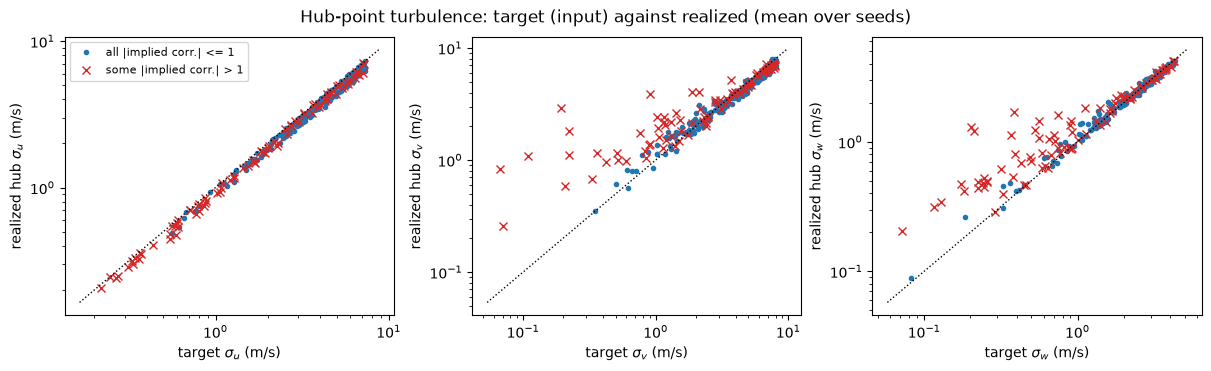

In [7]:
sig = {q: X[:, names.index('sig' + q)] for q in 'uvw'}
real = {q: col(f'hub_sig{q}_real') for q in 'uvw'}      # hub-point standard deviation, mean over the ok seeds
rho = {pc: X[:, names.index(pc)] / (sig[pc[2]] * sig[pc[3]]) for pc in ('PCuw', 'PCuv', 'PCvw')}
infeasible = np.zeros(len(X), bool)
for pc, r in rho.items():
    infeasible |= np.abs(r) > 1
    print(f'{pc}: |{pc} / (sigma_{pc[2]} sigma_{pc[3]})| > 1 in {int((np.abs(r) > 1).sum()):3d} sets (largest {np.abs(r).max():.1f})')
print(f'sets with at least one implied |correlation| > 1: {int(infeasible.sum())}')
for q in 'uvw':
    rat = real[q] / sig[q]
    print(f'realized / target sigma_{q} at the hub: median {np.median(rat):.3f}; range {rat.min():.3f} to {rat.max():.3f}; '
          f'where all implied |correlations| <= 1: {rat[~infeasible].min():.3f} to {rat[~infeasible].max():.3f}')
Lu = X[:, names.index('Lu')]
ratu = real['u'] / sig['u']
# variance share of the Kaimal spectrum (Eq. 7) above the lowest frequency 1/(660 s) of the periodic 660 s record:
# the integral of S_u from f0 to infinity is sigma_u^2 (1 + 6 f0 L_u / V_hub)^(-2/3)
frac = (1 + 6 * Lu / (660 * 12.0)) ** (-2 / 3)
print(f'realized / target sigma_u: median shortfall {1 - np.median(ratu):.1%}; correlation with L_u r = '
      f'{np.corrcoef(ratu, Lu)[0, 1]:.2f}; (realized / target)^2 against the Kaimal variance share above 1/(660 s), '
      f'(1 + 6 L_u / (660 s x 12 m/s))^(-2/3): r = {np.corrcoef(frac, ratu ** 2)[0, 1]:.2f} '
      f'(share {frac.min():.3f} to {frac.max():.3f}; median sqrt(share) {np.median(np.sqrt(frac)):.3f}, '
      f'median ratio {np.median(ratu):.3f})')
Umean = np.array([np.mean([float(r['Wind1VelX_mean']) for r in runs if int(r['set']) == s and r['status'] == 'ok'])
                  for s in range(len(sets))])
print(f'hub mean wind speed over the sets: {Umean.min():.3f} to {Umean.max():.3f} m/s (target 12 m/s)')
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
for ax, q in zip(axs, 'uvw'):
    ax.loglog(sig[q][~infeasible], real[q][~infeasible], '.', label='all |implied corr.| <= 1')
    ax.loglog(sig[q][infeasible], real[q][infeasible], 'x', color='C3', label='some |implied corr.| > 1')
    lim = [min(sig[q].min(), real[q].min()) * 0.8, max(sig[q].max(), real[q].max()) * 1.2]
    ax.plot(lim, lim, 'k:', lw=1)
    ax.set_xlabel(rf'target $\sigma_{q}$ (m/s)')
    ax.set_ylabel(rf'realized hub $\sigma_{q}$ (m/s)')
axs[0].legend(fontsize=8)
fig.suptitle('Hub-point turbulence: target (input) against realized (mean over seeds)');

**Per-set values against the per-run file**, and the seed noise of each per-set value, used below to judge how much of a quantity's variation the inputs could explain.

In [8]:
# sets.csv against the per-run file: ultimate = mean over ok seeds of max|x| (Eq. 5), DEL from the damage sums
worst = 0.0
for s in range(len(sets)):
    rr = [r for r in runs if int(r['set']) == s and r['status'] == 'ok']
    for c in QOI:
        v = np.mean([float(r[c + '_maxabs']) for r in rr])
        worst = max(worst, abs(v - float(sets[s][c + '_ult'])) / v)
    for c, mm in SN.items():
        v = (sum(float(r[c + '_dsum']) for r in rr) / (len(rr) * 600.0)) ** (1 / mm)
        worst = max(worst, abs(v - float(sets[s][c + '_DEL'])) / v)
print(f'sets.csv ultimate loads and DELs recomputed from runs.csv: largest relative difference {worst:.0e}')

# seed noise: variance of each set's value from the finite number of seeds (ultimate: var/S of the maxima;
# DEL: jackknife over seeds), averaged over the sets, as a share of the variance of the values over the sets
def seed_noise_share(q, keep):
    c, kind = q.rsplit('_', 1)
    se2 = []
    for s in np.flatnonzero(keep):
        rr = [r for r in runs if int(r['set']) == s and r['status'] == 'ok']
        if kind == 'ult':
            v = np.array([float(r[c + '_maxabs']) for r in rr])
            se2.append(v.var(ddof=1) / len(v))
        elif kind == 'DEL':
            d = np.array([float(r[c + '_dsum']) for r in rr])
            n = len(d)
            jk = ((d.sum() - d) / ((n - 1) * 600.0)) ** (1 / SN[c])
            se2.append((n - 1) / n * np.sum((jk - jk.mean()) ** 2))
        else:
            v = np.array([float(r['GenPwr_mean']) for r in rr])
            se2.append(v.var(ddof=1) / len(v))
    return np.mean(se2) / np.var(col(q)[keep])

sets.csv ultimate loads and DELs recomputed from runs.csv: largest relative difference 4e-16


### Which sets are analysed

The analysis uses the **284 sets in which all 30 seeds ran**, so that every per-set value averages the same 30 turbulence realizations (the seeds are common to all sets, which removes much of the seed-to-seed scatter from differences between sets). The rule leaves out sets with large $\sigma_u$ and small $\alpha$ more often than others; "Robustness" below repeats the main estimate with all 300 sets. The sets with a strong coherence modification ($\epsilon \geq 0.1$) and those with infeasible Reynolds stresses are kept, as the paper kept non-physical combinations [[1, p. 487]](https://doi.org/10.5194/wes-4-479-2019), and are checked separately below.

In [9]:
keep = n_ok == len(seeds)
Xk, Zk = X[keep], Z[keep]
print(f'sets analysed: {int(keep.sum())} of {len(X)} (all {len(seeds)} seeds ok); among them '
      f'{int((keep & nug).sum())} with coherence eps >= 0.1 and {int((keep & infeasible).sum())} with an implied '
      f'|correlation| > 1')

sets analysed: 284 of 300 (all 30 seeds ok); among them 26 with coherence eps >= 0.1 and 83 with an implied |correlation| > 1


### Estimating the subspace without gradients

There are no gradients, and with seed noise and 18 inputs, local linear fits (`'opg'`) would be poorly determined. Two global fits are used, both in the normalized inputs on $[-1, 1]^{18}$:

* **`'ols'`**: a linear least-squares fit $f \approx u_0 + \mathbf u^T\mathbf x$, whose normalized gradient $\mathbf w_1 = \mathbf u/\|\mathbf u\|$ is a single direction (19 coefficients). This is the main estimate of $\mathbf w_1$, with 500 bootstrap replicates of the sets. Its sign makes $f$ increase along $\mathbf w_1$ (`ac.orient(..., by='covariance')`).
* **`'qphd'`**: a quadratic fit $q(\mathbf x) = c + \mathbf g^T\mathbf x + \tfrac12\mathbf x^T\mathbf H\mathbf x$ (190 coefficients), and $\mathbf C = \mathbb E[\nabla q\,\nabla q^T] = \mathbf g\mathbf g^T + \mathbf H\Sigma\mathbf H$ with $\Sigma = \tfrac13\mathbf I$ for uniform inputs on $[-1, 1]$. This is exactly the active-subspace matrix of the fitted quadratic, so it gives eigenvalues, a second direction and activity scores, and it sees curvature in an input, which a linear fit cannot. Its eigenvectors are signed by the same covariance rule.

Both estimators are justified for Gaussian inputs by Stein's lemma. On a uniform space they are read as fits whose gradients define the matrix, hence the muted `ValidityWarning`. The bootstrap does not suit `'qphd'` here: a bootstrap replicate of the 284 sets holds about 180 distinct sets, fewer than the 190 coefficients. Its stability is judged instead by refitting on 100 random subsamples of 90 % of the sets (255 sets) and measuring the distance between the subspaces; this understates the sampling variability of the full fit. The fit of each low-dimensional model is measured by 10-fold cross-validation, with the subspace re-estimated in each fold.

### Results for four loads

Four loads are examined in detail: the ultimate and fatigue (DEL) out-of-plane bending moment at the root of blade 1, and the ultimate and fatigue fore-aft bending moment at the tower base. Printed per load: the `'qphd'` eigenvalue ratios $\lambda_1/\lambda_2$ and $\lambda_2/\lambda_3$ and the share of the trace in $\lambda_1$; the median and 5th percentile over the bootstrap of $|\mathbf w_1^T\mathbf w_1^{(b)}|$ for the OLS direction; the agreement $|\mathbf w_{1,\mathrm{ols}}^T\mathbf w_{1,\mathrm{qphd}}|$; the 10-fold cross-validated $R^2$ of a quadratic in one (OLS) or two (`'qphd'`) active variables; the leave-one-out $R^2$ of the full 18-input quadratic; and the seed-noise share of the variance (the mean squared standard error of a set's value from its 30 seeds, divided by the variance of the values across sets).

In [10]:
HEAD4 = ['RootMyc1_ult', 'TwrBsMyt_ult', 'RootMyc1_DEL', 'TwrBsMyt_DEL']
TITLE = {'RootMyc1_ult': 'blade-root OoP bending, ultimate (kN m)', 'TwrBsMyt_ult': 'tower-base FA bending, ultimate (kN m)',
         'RootMyc1_DEL': 'blade-root OoP bending, DEL (kN m)', 'TwrBsMyt_DEL': 'tower-base FA bending, DEL (kN m)'}
NBOOT = 500


def fit(q, mask, nboot=0):
    """OLS direction (with bootstrap) and the qphd eigenpairs for the column q of sets.csv on the sets in mask."""
    f, Xm = col(q)[mask], X[mask]
    ols = ac.active_subspace(space=space, X=Xm, f=f, estimator='ols', n=1, nboot=nboot,
                             bootstrap_vectors=1 if nboot else 0, rng=rng if nboot else None, qoi=q)
    ols = ac.orient(ols, by='covariance', X=Xm, f=f)
    qp = ac.active_subspace(space=space, X=Xm, f=f, estimator='qphd', n=2, qoi=q)
    qp = ac.orient(qp, by='covariance', X=Xm, f=f, columns=2)
    return ols, qp


def cv_r2(q, dims, folds=10):
    """10-fold cross-validated R^2 of a quadratic in the active variables, the subspace re-estimated in each fold
    (1: the OLS direction; 2: the leading two qphd directions)."""
    f = col(q)[keep]
    M = len(f)
    pred = np.empty(M)
    for te in np.array_split(rng.permutation(M), folds):
        tr = np.setdiff1d(np.arange(M), te)
        est = 'ols' if dims == 1 else 'qphd'
        s = ac.active_subspace(space=space, X=Xk[tr], f=f[tr], estimator=est, n=dims)
        pred[te] = ac.predict(ac.fit_surrogate(X=Xk[tr], f=f[tr], subspace=s, kind='poly', degree=2), Xk[te])
    return 1 - np.sum((f - pred) ** 2) / np.sum((f - f.mean()) ** 2)


def subsample_distances(q, qp, K=4, nsub=100, frac=0.9):
    """Distances ||W_1^T W_2'|| between the qphd subspaces of dimension 1..K from all sets and from 90 % subsamples."""
    f = col(q)[keep]
    M = len(f)
    d = np.empty((nsub, K))
    for b in range(nsub):
        idx = rng.choice(M, int(frac * M), replace=False)
        W = ac.active_subspace(space=space, X=Xk[idx], f=f[idx], estimator='qphd', n=1).W
        for k in range(1, K + 1):
            d[b, k - 1] = np.linalg.norm(qp.W[:, :k].T @ W[:, k:], 2)
    return d


res = {}
print(f"{'QoI':13s} {'l1/l2':>6s} {'l2/l3':>6s} {'l1/tr':>6s} {'|w.wb| med':>10s} {'5%':>6s} {'|wols.wq|':>9s} "
      f"{'CV 1-D':>7s} {'CV 2-D':>7s} {'LOO 18-D':>8s} {'noise':>6s}")
for q in HEAD4:
    ols, qp = fit(q, keep, nboot=NBOOT)
    lam = qp.eigenvalues
    cb = np.abs(ols.bootstrap_eigenvectors[:, :, 0] @ ols.W[:, 0])
    full = ac.fit_surrogate(X=Xk, f=col(q)[keep], space=space, subspace=None, kind='poly', degree=2)
    res[q] = dict(ols=ols, qp=qp, cb=cb, cv1=cv_r2(q, 1), cv2=cv_r2(q, 2), loo18=full.loo_r_squared,
                  noise=seed_noise_share(q, keep), dist=subsample_distances(q, qp))
    r = res[q]
    print(f'{q:13s} {lam[0] / lam[1]:6.2f} {lam[1] / lam[2]:6.2f} {lam[0] / lam.sum():6.3f} {np.median(cb):10.4f} '
          f'{np.quantile(cb, 0.05):6.4f} {abs(ols.W[:, 0] @ qp.W[:, 0]):9.4f} {r["cv1"]:7.3f} {r["cv2"]:7.3f} '
          f'{r["loo18"]:8.3f} {r["noise"]:6.3f}')
M = int(keep.sum())
print(f'\nqphd fits {(m + 1) * (m + 2) // 2} coefficients to {M} sets; a bootstrap replicate holds on average '
      f'{M * (1 - (1 - 1 / M) ** M):.0f} distinct sets, a 90 % subsample {int(0.9 * M)}')

QoI            l1/l2  l2/l3  l1/tr |w.wb| med     5% |wols.wq|  CV 1-D  CV 2-D LOO 18-D  noise


RootMyc1_ult    4.68   2.62  0.676     0.9954 0.9917    0.9947   0.857   0.893    0.869  0.004


TwrBsMyt_ult   10.24   1.93  0.751     0.9935 0.9870    0.9758   0.825   0.870    0.790  0.003


RootMyc1_DEL    2.94   4.60  0.621     0.9944 0.9893    0.9914   0.835   0.893    0.866  0.023


TwrBsMyt_DEL   14.34   2.16  0.830     0.9954 0.9913    0.9877   0.880   0.902    0.817  0.012

qphd fits 190 coefficients to 284 sets; a bootstrap replicate holds on average 180 distinct sets, a 90 % subsample 255


**Eigenvalues and subspace distances.** The first `'qphd'` eigenvalue is 2.9 to 14 times the second for these loads. For three of them the gap after the first eigenvalue is the largest; for the blade-root DEL the gap after the second is larger ($\lambda_2/\lambda_3 = 4.6$ against $\lambda_1/\lambda_2 = 2.9$), so a two-dimensional subspace is indicated there, and two variables raise its cross-validated $R^2$ from 0.835 to 0.893. For all four, the distances between the one-dimensional subspaces of all sets and of 90 % subsamples are small. The distances grow with the dimension: the second direction is moderately well determined for the blade-root loads and poorly for the tower-base loads, and from three dimensions on the subspaces are not well determined by 284 sets.

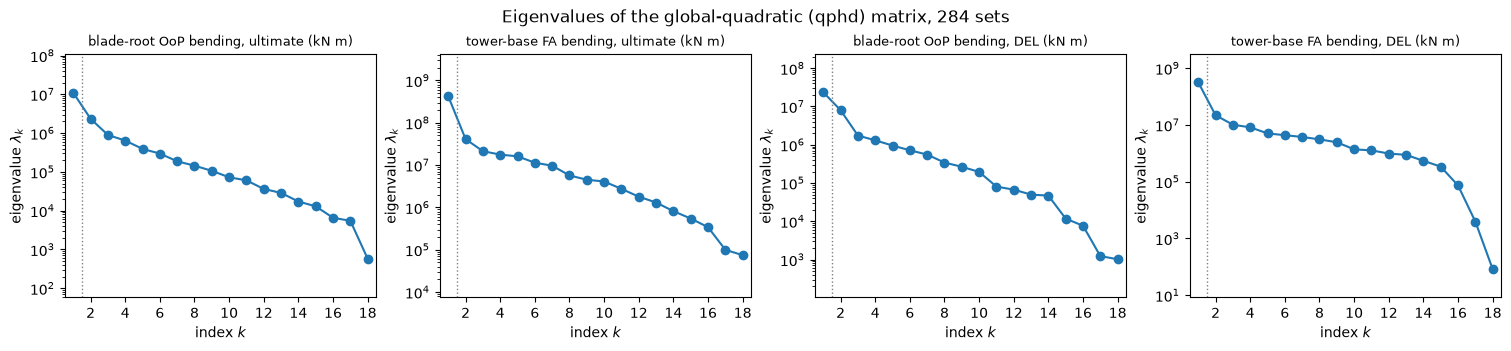

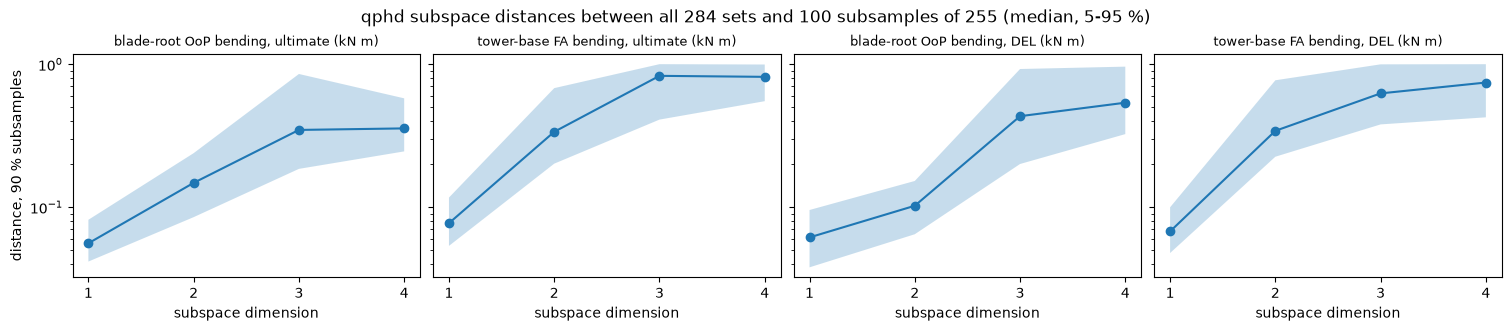

In [11]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4), constrained_layout=True)
for ax, q in zip(axs, HEAD4):
    ac.plotting.plot_eigenvalues(ac.with_dimension(res[q]['qp'], 1), ax=ax, interval='none')
    ax.set_title(TITLE[q], fontsize=9)
fig.suptitle('Eigenvalues of the global-quadratic (qphd) matrix, 284 sets');
fig, axs = plt.subplots(1, 4, figsize=(15, 3.2), constrained_layout=True, sharey=True)
for ax, q in zip(axs, HEAD4):
    d = res[q]['dist']
    k = np.arange(1, d.shape[1] + 1)
    ax.semilogy(k, np.median(d, 0), 'o-')
    ax.fill_between(k, np.quantile(d, 0.05, 0), np.quantile(d, 0.95, 0), alpha=0.25, lw=0)
    ax.set_xticks(k)
    ax.set_xlabel('subspace dimension')
    ax.set_title(TITLE[q], fontsize=9)
axs[0].set_ylabel('distance, 90 % subsamples')
fig.suptitle('qphd subspace distances between all 284 sets and 100 subsamples of 255 (median, 5-95 %)');

**The first direction.** For all four loads $\mathbf w_1$ is led by $\sigma_u$, the standard deviation of the along-wind turbulence. For the blade-root moment the shear exponent $\alpha$ comes second, then the $u$ coherence parameters $a_u$ and $b_u$ (negative: slower coherence decay, larger loads); for the tower-base moment the $u$ integral scale $L_u$ comes second (negative), then $a_u$ and $\gamma$. Part of the weight of $L_u$ may come from the realized $\sigma_u$ falling further below its target where $L_u$ is large ("Realized turbulence"): with the realized hub $\sigma_u$ in place of the target, the weight of $L_u$ on the tower-base ultimate load shrinks from $-0.353$ to $-0.286$ ("Robustness"). The bootstrap bands are narrow: $|\mathbf w_1^T\mathbf w_1^{(b)}| \geq 0.987$ for 95 % of the replicates of each load.

RootMyc1_ult  sigu +0.845, alpha +0.373, au -0.195, bu -0.164, gamma +0.158
TwrBsMyt_ult  sigu +0.824, Lu -0.353, au -0.236, gamma +0.210, alpha +0.184
RootMyc1_DEL  sigu +0.840, alpha +0.412, au -0.190, bu -0.178, gamma +0.134
TwrBsMyt_DEL  sigu +0.906, Lu -0.296, au -0.176, gamma +0.169, sigw +0.092


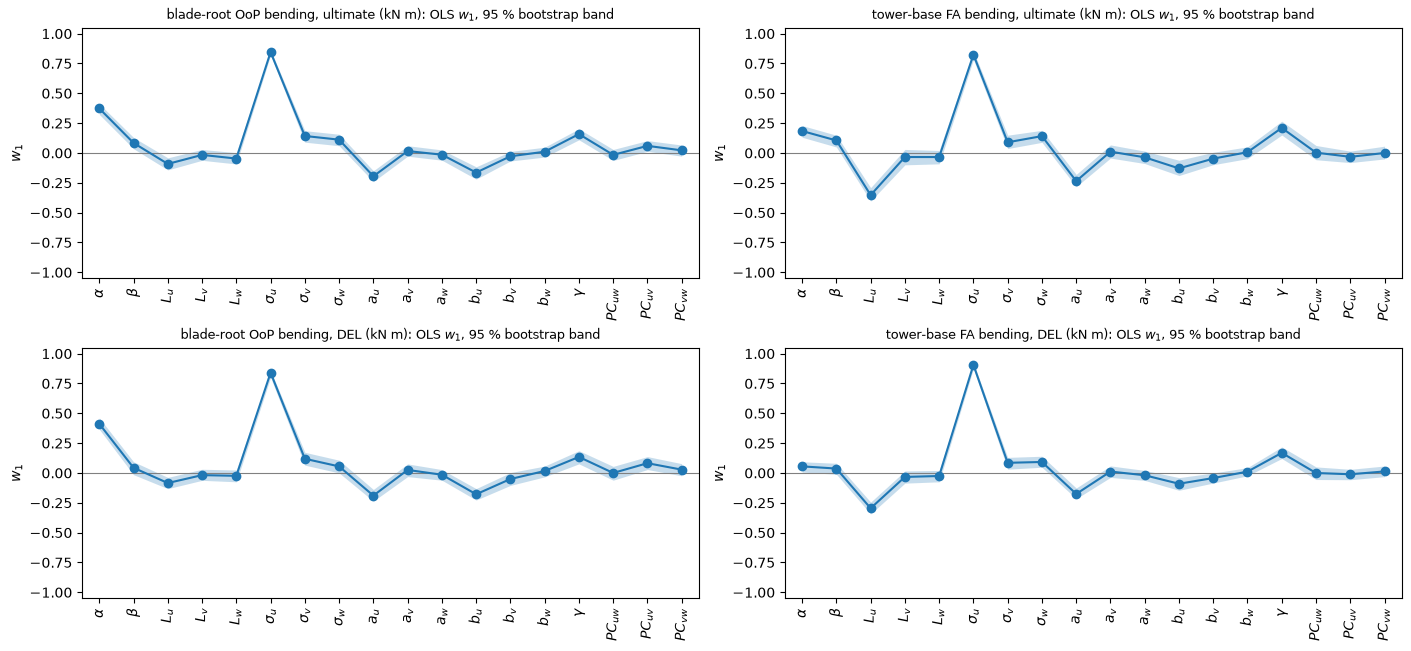

In [12]:
fig, axs = plt.subplots(2, 2, figsize=(14, 6.4), constrained_layout=True)
for ax, q in zip(axs.ravel(), HEAD4):
    ac.plotting.plot_eigenvectors(res[q]['ols'], indices=[0], labels=labels, interval='percentile', ax=[ax])
    ax.set_title(TITLE[q] + r': OLS $w_1$, 95 % bootstrap band', fontsize=9)
for q in HEAD4:
    w = res[q]['ols'].W[:, 0]
    print(f'{q:13s} ' + ', '.join(f'{names[j]} {w[j]:+.3f}' for j in np.argsort(-np.abs(w))[:5]))

**Sufficient summary plots.** Each load rises smoothly, slightly convexly, along $y_1$. A quadratic in $y_1$ has cross-validated $R^2$ from 0.825 to 0.880; the seed noise is at most 2.3 % of the variance, so most of the remaining scatter is dependence on the inputs outside $\mathbf w_1$. Two `'qphd'` variables raise the cross-validated $R^2$ to between 0.870 and 0.902; the second direction (printed below for all four loads) is mainly $\alpha$ for the blade root and $L_u$ for the tower base. The sets with infeasible Reynolds stresses or a strong coherence modification lie among the others. The two-variable plots of the ultimate loads show the second direction as a colour gradient across the band of points.

RootMyc1_ult  quadratic in y1: in-sample R^2 0.879, LOO R^2 0.876 (subspace not re-estimated), 10-fold CV R^2 0.857
TwrBsMyt_ult  quadratic in y1: in-sample R^2 0.860, LOO R^2 0.855 (subspace not re-estimated), 10-fold CV R^2 0.825
RootMyc1_DEL  quadratic in y1: in-sample R^2 0.858, LOO R^2 0.855 (subspace not re-estimated), 10-fold CV R^2 0.835
TwrBsMyt_DEL  quadratic in y1: in-sample R^2 0.901, LOO R^2 0.897 (subspace not re-estimated), 10-fold CV R^2 0.880
RootMyc1_ult  qphd w2: alpha -0.90, sigu +0.29, bu -0.24, PCvw +0.12
TwrBsMyt_ult  qphd w2: Lu +0.69, sigu +0.49, alpha +0.37, au +0.27
RootMyc1_DEL  qphd w2: alpha +0.91, sigu -0.30, bu +0.18, gamma -0.15
TwrBsMyt_DEL  qphd w2: Lu +0.65, au +0.44, sigu +0.44, sigv +0.27


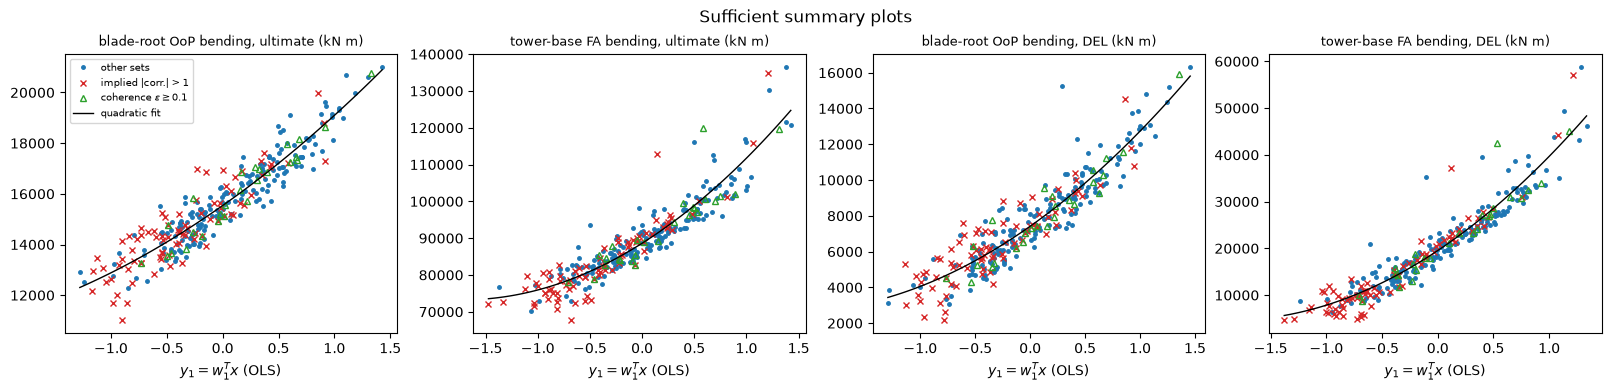

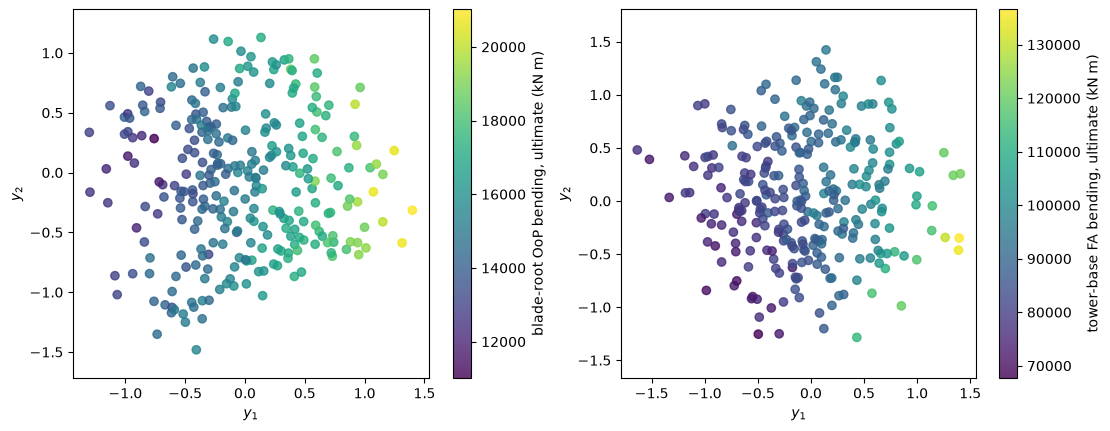

In [13]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), constrained_layout=True)
for ax, q in zip(axs, HEAD4):
    f = col(q)[keep]
    y = Zk @ res[q]['ols'].W[:, 0]
    g = ac.fit_surrogate(X=Xk, f=f, subspace=res[q]['ols'], kind='poly', degree=2)
    clean = ~(infeasible[keep] | nug[keep])
    ax.plot(y[clean], f[clean], '.', color='C0', ms=5, label='other sets')
    ax.plot(y[infeasible[keep]], f[infeasible[keep]], 'x', color='C3', ms=4, label='implied |corr.| > 1')
    ax.plot(y[nug[keep]], f[nug[keep]], '^', mfc='none', color='C2', ms=5, label=r'coherence $\epsilon \geq 0.1$')
    yy = np.linspace(y.min(), y.max(), 100)
    ax.plot(yy, g.evaluate(yy[:, None]), 'k-', lw=1, label='quadratic fit')
    ax.set_xlabel(r'$y_1 = w_1^T x$ (OLS)')
    ax.set_title(TITLE[q], fontsize=9)
    print(f'{q:13s} quadratic in y1: in-sample R^2 {1 - np.var(g.residuals) / np.var(f):.3f}, LOO R^2 '
          f'{g.loo_r_squared:.3f} (subspace not re-estimated), 10-fold CV R^2 {res[q]["cv1"]:.3f}')
axs[0].legend(fontsize=7)
fig.suptitle('Sufficient summary plots');
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
for ax, q in zip(axs, ['RootMyc1_ult', 'TwrBsMyt_ult']):
    ac.plotting.plot_sufficient_summary(res[q]['qp'], X=Xk, f=col(q)[keep], dims=2, ax=ax, qoi_label=TITLE[q])
for q in HEAD4:
    w2 = res[q]['qp'].W[:, 1]
    print(f'{q:13s} qphd w2: ' + ', '.join(f'{names[j]} {w2[j]:+.2f}' for j in np.argsort(-np.abs(w2))[:4]))

### All loads and the power

The same estimates for every quantity of interest: its range over the 284 sets, the `'qphd'` ratios $\lambda_1/\lambda_2$ and $\lambda_2/\lambda_3$, the dimension $n$ at the largest of the first three eigenvalue gaps $\lambda_k/\lambda_{k+1}$ (this data set's rule), the agreement of the OLS and `'qphd'` first directions, the cross-validated $R^2$ of a quadratic in the OLS variable $y_1$, the leave-one-out $R^2$ of the full 18-input quadratic, the seed-noise share, the three largest entries of the OLS $\mathbf w_1$, and the three largest activity scores of the `'qphd'` matrix (with $n = 18$, as shares of the trace).

The along-wind turbulence $\sigma_u$ dominates almost everything. The rule gives $n = 2$ for 9 of the 30 quantities (listed below the table) and $n = 1$ for the others; for the four fatigue loads whose seed noise is more than 30 % of the variance (31 % to 76 %: `RootMxc1_DEL`, `RootMzc1_DEL`, `RotTorq_DEL`, `YawBrMxp_DEL`; cross-validated $R^2$ 0.066 to 0.609), no subspace is well determined, whatever $n$, so 2 of the 9 with $n = 2$ (`RotTorq_DEL`, `YawBrMxp_DEL`) have no well-determined subspace. The exceptions and weak cases are informative. The in-plane (edgewise) blade-root DEL and the blade pitching-moment DEL vary little with the inflow: seed noise is 76 % and 54 % of their variance, the cross-validated $R^2$ is 0.066 and 0.316, and their first directions are not well determined (in-plane bending of a rotating blade is dominated by its weight). The rotor-torque and tower-top side-side DELs also have large seed noise. For the low-speed-shaft DELs the OLS and `'qphd'` directions disagree ($|\mathbf w_{1,\mathrm{ols}}^T\mathbf w_{1,\mathrm{qphd}}| \approx 0.78$), and the activity scores put $\alpha$ first: the DEL is smallest at an intermediate shear exponent inside the range and grows on both sides of it (figure below), a curvature in $\alpha$ that a linear fit cannot see. The mean electrical power stays between 3845 and 4998 kW, held near rated by the controller; it falls with $\sigma_u$ and rises with $b_u$ and $a_u$.

In [14]:
ALL = [c + '_ult' for c in QOI] + [c + '_DEL' for c in SN] + ['GenPwr_mean']
top3, top3_act, ngap, noise, cv = {}, {}, {}, {}, {}
print(f"{'QoI':14s} {'range over the 284 sets':>24s} {'l1/l2':>6s} {'l2/l3':>6s} {'n':>2s} {'|wols.wq|':>9s} {'CV 1-D':>7s} {'LOO 18-D':>8s} "
      f"{'noise':>6s}  {'leading OLS w1 entries':32s} leading activity scores (qphd, n = 18)")
for q in ALL:
    f = col(q)[keep]
    ols, qp = fit(q, keep)
    w = ols.W[:, 0]
    act = ac.activity_scores(qp, n=m)
    act = act / act.sum()
    top3[q] = [names[j] for j in np.argsort(-np.abs(w))[:3]]
    top3_act[q] = [names[j] for j in np.argsort(-act)[:3]]
    lam = qp.eigenvalues
    ngap[q] = 1 + int(np.argmax(lam[:3] / lam[1:4]))     # dimension at the largest of the first three eigenvalue gaps
    noise[q] = seed_noise_share(q, keep)
    full = ac.fit_surrogate(X=Xk, f=f, space=space, subspace=None, kind='poly', degree=2)
    cv1 = cv[q] = res[q]['cv1'] if q in res else cv_r2(q, 1)
    print(f'{q:14s} {f.min():11.4g} to {f.max():9.4g} {lam[0] / lam[1]:6.2f} {lam[1] / lam[2]:6.2f} {ngap[q]:2d} '
          f'{abs(w @ qp.W[:, 0]):9.3f} {cv1:7.3f} {full.loo_r_squared:8.3f} {noise[q]:6.3f}  '
          + f'{", ".join(f"{names[j]} {w[j]:+.2f}" for j in np.argsort(-np.abs(w))[:3]):32s} '
          + ', '.join(f'{names[j]} {act[j]:.2f}' for j in np.argsort(-act)[:3]))
print('\nn (largest of the first three qphd eigenvalue gaps): '
      + '; '.join(f'n = {k}: {sum(v == k for v in ngap.values())}' for k in (1, 2, 3))
      + ' | n > 1: ' + ', '.join(f'{q} ({ngap[q]})' for q in ALL if ngap[q] > 1))
noisy = [q for q in ALL if noise[q] > 0.3]     # seed noise above 30 % of the variance (this data set's line)
print(f'seed noise > 30 % of the variance: {len(noisy)} ({", ".join(noisy)}; CV 1-D '
      f'{min(cv[q] for q in noisy):.3f} to '
      f'{max(cv[q] for q in noisy):.3f}); of the n > 1 quantities: '
      f'{sum(ngap[q] > 1 for q in noisy)} of {sum(v > 1 for v in ngap.values())} '
      f'({", ".join(q for q in noisy if ngap[q] > 1)})')
lead = [top3[q][0] for q in ALL[:-1]]
print(f'\nsigma_u leads OLS w1 for {lead.count("sigu")} of the {len(lead)} load QoIs; the others: '
      + ', '.join(f'{q} ({top3[q][0]})' for q in ALL[:-1] if top3[q][0] != 'sigu'))
lead = [top3_act[q][0] for q in ALL[:-1]]
print(f'sigma_u has the largest activity score for {lead.count("sigu")} of the {len(lead)} load QoIs; the others: '
      + ', '.join(f'{q} ({top3_act[q][0]})' for q in ALL[:-1] if top3_act[q][0] != 'sigu'))
print(f'alpha among the three largest activity scores for {sum("alpha" in top3_act[q] for q in ALL[:-1])} of the '
      f'{len(ALL) - 1} load QoIs')

QoI             range over the 284 sets  l1/l2  l2/l3  n |wols.wq|  CV 1-D LOO 18-D  noise  leading OLS w1 entries           leading activity scores (qphd, n = 18)


RootMyc1_ult     1.101e+04 to 2.102e+04   4.68   2.62  1     0.995   0.857    0.869  0.004  sigu +0.85, alpha +0.37, au -0.20 sigu 0.49, alpha 0.21, bu 0.06


RootMxc1_ult          5193 to 1.175e+04  13.01   1.25  1     0.986   0.849    0.797  0.039  sigu +0.79, alpha +0.40, au -0.22 sigu 0.50, alpha 0.10, au 0.08


RootMzc1_ult         76.51 to     303.1   8.97   2.29  1     0.989   0.844    0.837  0.011  sigu +0.83, sigv +0.31, alpha +0.23 sigu 0.56, sigv 0.10, au 0.06


RootMyc2_ult     1.102e+04 to 2.096e+04   5.15   2.28  1     0.994   0.858    0.861  0.004  sigu +0.84, alpha +0.38, au -0.20 sigu 0.49, alpha 0.20, bu 0.06


RootMyc3_ult     1.102e+04 to 2.152e+04   4.92   2.58  1     0.994   0.856    0.855  0.005  sigu +0.84, alpha +0.38, au -0.19 sigu 0.49, alpha 0.20, bu 0.06


... (21 outputs left out)

YawBrMzp_DEL         639.4 to 1.155e+04  36.55   1.43  1     0.998   0.961    0.941  0.002  sigu +0.98, Lu -0.10, gamma +0.09 sigu 0.86, gamma 0.02, au 0.02


TwrBsMyt_DEL          4638 to 5.886e+04  14.34   2.16  1     0.988   0.880    0.817  0.012  sigu +0.91, Lu -0.30, au -0.18   sigu 0.63, Lu 0.14, au 0.06


TwrBsMxt_DEL          2206 to 3.072e+04   3.50   3.47  1     0.947   0.656    0.547  0.062  sigu +0.79, Lu -0.38, sigv +0.29 sigu 0.39, Lu 0.19, sigv 0.10


GenPwr_mean           3845 to      4998   5.65   1.45  1     0.922   0.524    0.496  0.002  bu +0.59, sigu -0.43, au +0.43   bu 0.39, au 0.12, sigu 0.10

n (largest of the first three qphd eigenvalue gaps): n = 1: 21; n = 2: 9; n = 3: 0 | n > 1: LSSGagMya_ult (2), LSSGagMza_ult (2), YawBrMyp_ult (2), RootMyc1_DEL (2), RootMyc2_DEL (2), LSSGagMya_DEL (2), LSSGagMza_DEL (2), RotTorq_DEL (2), YawBrMxp_DEL (2)
seed noise > 30 % of the variance: 4 (RootMxc1_DEL, RootMzc1_DEL, RotTorq_DEL, YawBrMxp_DEL; CV 1-D 0.066 to 0.609); of the n > 1 quantities: 2 of 9 (RotTorq_DEL, YawBrMxp_DEL)

sigma_u leads OLS w1 for 28 of the 29 load QoIs; the others: RootMxc1_DEL (alpha)
sigma_u has the largest activity score for 25 of the 29 load QoIs; the others: RootMxc1_DEL (sigv), RootMzc1_DEL (sigv), LSSGagMya_DEL (alpha), LSSGagMza_DEL (alpha)
alpha among the three largest activity scores for 17 of the 29 load QoIs


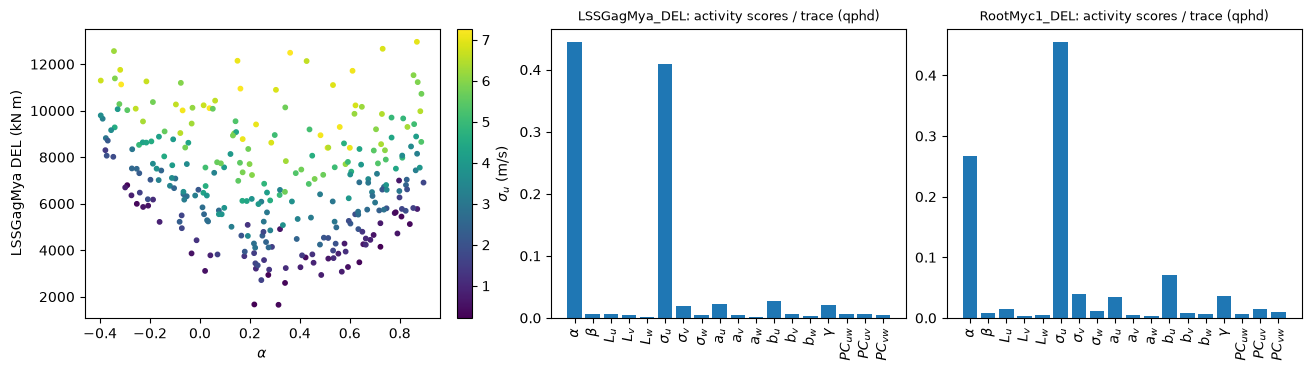

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
q = 'LSSGagMya_DEL'
sc = axs[0].scatter(Xk[:, names.index('alpha')], col(q)[keep], c=Xk[:, names.index('sigu')], s=10, cmap='viridis')
axs[0].set_xlabel(r'$\alpha$')
axs[0].set_ylabel('LSSGagMya DEL (kN m)')
fig.colorbar(sc, ax=axs[0], label=r'$\sigma_u$ (m/s)')
for ax, q in zip(axs[1:], ['LSSGagMya_DEL', 'RootMyc1_DEL']):
    _, qp = fit(q, keep)
    a = ac.activity_scores(qp, n=m)
    ax.bar(range(m), a / a.sum())
    ax.set_xticks(range(m))
    ax.set_xticklabels(labels, rotation=90)
    ax.set_title(f'{q}: activity scores / trace (qphd)', fontsize=9)

### Robustness

The OLS direction of each of the four loads, re-estimated on other choices of sets, against the main estimate ($|\mathbf w_1^T\mathbf w_1'|$): all 300 sets, with each failed run left out of its set's mean; the 284 sets less the 26 with a coherence modification $\epsilon \geq 0.1$; and the 284 less the 83 with an infeasible Reynolds stress. All agree to better than 0.995, so neither the failed runs, nor the TurbSim patch, nor the infeasible stresses change the first direction appreciably. These checks do not cover the per-component ultimate loads: whether the paper's vector sums would give other directions cannot be tested from the stored files.

The second print replaces the target $\sigma_u$ (the TurbSim input) by the realized hub $\sigma_u$, normalized over its own range, and re-estimates the OLS direction. The weight of $\sigma_u$ grows a little and that of $L_u$ shrinks: on the tower-base loads, from $-0.353$ to $-0.286$ (ultimate) and from $-0.296$ to $-0.222$ (DEL). Part of the influence of $L_u$ on the tower-base loads may therefore be the record-length effect on the realized $\sigma_u$ rather than the integral scale itself.

In [16]:
variants = {'all 300 sets (failed runs left out of each mean)': np.ones(len(X), bool),
            '284 sets without coherence eps >= 0.1': keep & ~nug,
            '284 sets without implied |corr.| > 1': keep & ~infeasible}
print(f"{'variant':52s} {'sets':>4s}  " + '  '.join(f'{q:>12s}' for q in HEAD4))
for v, mask in variants.items():
    cos = [abs(fit(q, mask)[0].W[:, 0] @ res[q]['ols'].W[:, 0]) for q in HEAD4]
    print(f'{v:52s} {int(mask.sum()):4d}  ' + '  '.join(f'{c:12.4f}' for c in cos))
# the OLS direction with the realized hub sigma_u (sets.csv, hub_sigu_real) in place of its target, normalized over
# the range of the realized values; the other 17 inputs unchanged
ju, jl = names.index('sigu'), names.index('Lu')
Xr = X.copy()
Xr[:, ju] = real['u']
lo_r, hi_r = lower.copy(), upper.copy()
lo_r[ju], hi_r[ju] = real['u'].min(), real['u'].max()
space_r = ac.Uniform(lo_r, hi_r, names=names)
print('\nOLS w1 with the target sigma_u (main estimate) and with the realized hub sigma_u:')
for q in HEAD4:
    f = col(q)[keep]
    s = ac.orient(ac.active_subspace(space=space_r, X=Xr[keep], f=f, estimator='ols', n=1), by='covariance', X=Xr[keep], f=f)
    w0, w = res[q]['ols'].W[:, 0], s.W[:, 0]
    print(f'  {q:13s} sigu {w0[ju]:+.3f} -> {w[ju]:+.3f}, Lu {w0[jl]:+.3f} -> {w[jl]:+.3f}')

variant                                              sets  RootMyc1_ult  TwrBsMyt_ult  RootMyc1_DEL  TwrBsMyt_DEL
all 300 sets (failed runs left out of each mean)      300        0.9976        0.9980        0.9973        0.9992
284 sets without coherence eps >= 0.1                 258        0.9997        0.9992        0.9995        0.9995
284 sets without implied |corr.| > 1                  201        0.9961        0.9967        0.9952        0.9979

OLS w1 with the target sigma_u (main estimate) and with the realized hub sigma_u:
  RootMyc1_ult  sigu +0.845 -> +0.874, Lu -0.092 -> -0.030
  TwrBsMyt_ult  sigu +0.824 -> +0.866, Lu -0.353 -> -0.286
  RootMyc1_DEL  sigu +0.840 -> +0.869, Lu -0.084 -> -0.024
  TwrBsMyt_DEL  sigu +0.906 -> +0.938, Lu -0.296 -> -0.222


### Relation to the paper's conclusions

These runs were not designed to reproduce the paper's results. They cover the near-rated bin only, whereas the paper's rankings pool three wind-speed bins, and their simulation settings differ from the paper's (table below). The paper ranks the inputs by how often their elementary effects exceed a threshold, a different measure from the activity scores used here. The results above therefore stand on their own.

For orientation, the paper states: "Overall, 46 % of the outliers for both ultimate and fatigue loads are due to u-direction turbulence standard deviation ($\sigma_u$) and 26 % for vertical shear ($\alpha$); for all but two QoIs, these are the most sensitive parameters" [[1, p. 490]](https://doi.org/10.5194/wes-4-479-2019), and "Secondary parameters of importance are identified as veer, u-direction integral length, and u components of the IEC coherence model, as well as the exponent" [[1, p. 479]](https://doi.org/10.5194/wes-4-479-2019). Here, too, $\sigma_u$ leads for most loads (25 of 29 by activity score), and the secondary inputs ($\alpha$, $a_u$, $b_u$, $L_u$, $\gamma$, and also $\sigma_v$) largely overlap with the paper's. The shear exponent $\alpha$ is less prominent here: it is among the three largest activity scores for 17 of the 29 loads and leads only the low-speed-shaft fatigue loads. One possible reason is in the paper's text: its shear sensitivity comes mostly from the below-rated bin, where its range for $\alpha$ is much wider ($-0.75$ to $3.3$, against $-0.4$ to $0.9$ near rated; Table 3 prints $-1.5$ as the below-rated minimum, with the footnote that it was changed to $-0.75$ "due to simulation issues") [[1, pp. 486-487]](https://doi.org/10.5194/wes-4-479-2019), and this data set has only the near-rated bin. The paper also finds $L_u$ of secondary importance; here part of its weight on the tower-base loads may be the record-length effect on the realized $\sigma_u$ ("Robustness"), which would apply to the paper's runs only if they had a similar shortfall. Whether the other differences in settings (wind-grid resolution, per-component rather than vector-sum ultimate loads, tower drag, the coherence patch) also contribute cannot be determined from the paper's text and these runs.

### Settings: the paper and this data set

| | paper | this data set |
|---|---|---|
| turbine | NREL 5 MW reference turbine, p. 480; the variant (land-based or offshore) is not stated | land-based model of the OpenFAST regression tests, case `5MW_Land_DLL_WTurb`, with the baseline DISCON controller |
| codes | OpenFAST, version not stated ("OpenFAST (2017)", p. 480; the reference is the online documentation, dated November 2017, p. 512) | OpenFAST and TurbSim v3.5.5 |
| wind-speed bins | 8, 12 and 18 m/s, p. 480 | 12 m/s only |
| design | radial elementary effects: 30 Sobol starting points, steps of 10 % of each range, 19 points each, pp. 483 and 487 | 300 independent uniform draws on the ranges (seed 20261112) |
| seeds | 30 per point, p. 487; whether the same for every point is not stated | 30, the same for every set |
| analysis subset | not stated | 284 of the 300 sets, those with all 30 seeds complete |
| mean wind profile | power-law shear $\alpha$ and a linear veer, $\beta$ the total veer across the turbine, centred on the hub, p. 485; the direction outside the rotor is not stated | TurbSim user-defined profile (`USR`), $12\,(z/90)^\alpha$ m/s at 5-200 m, direction $\beta (z - 90)/126$ within the rotor (27-153 m) and held at the edge values outside |
| spectrum, Eq. 7 | denominator printed with $L_1$, p. 485 | $L_q$ |
| non-positive-definite coherence | not stated | off-diagonals scaled by $1/(1+\epsilon)$ (patched TurbSim), 38 sets |
| wind grid | 25 × 25 points covering the rotor, p. 480 | 15 × 15 points, 145 m square |
| transient | 30 s, then 10 min, p. 480 | 60 s, then 600 s |
| tower drag | not considered, p. 480 | AeroDyn tower loads on (`TwrAero = True` in the regression-test case) |
| ultimate bending moments | largest vector sum of the first two components, p. 481 | each component separately; the vector sum cannot be formed from the stored maxima |
| DEL | MLife, no Goodman correction, zero fixed mean, p. 483; S-N exponents and equivalent frequency not given | same conventions; $m = 10$ (blade root) and 4 (others), 1 Hz, 600 s |

### References

[1] A. N. Robertson, K. Shaler, L. Sethuraman, and J. Jonkman. [Sensitivity analysis of the effect of wind characteristics and turbine properties on wind turbine loads](https://doi.org/10.5194/wes-4-479-2019). *Wind Energy Science*, 4:479–513, 2019. Published version; page numbers are the printed ones.

[2] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, Philadelphia, 2015.

[3] P. G. Constantine and P. Diaz. [Global sensitivity metrics from active subspaces](https://doi.org/10.1016/j.ress.2017.01.013). *Reliability Engineering & System Safety*, 162:1–13, 2017.

[4] OpenFAST, git tag [v3.5.5](https://github.com/OpenFAST/openfast/tree/v3.5.5) (commit b48e032303c12df6949c67ebffb7050b888db000), with TurbSim and the regression-test inputs (`reg_tests/r-test`). Apache License 2.0.

[5] J. Jonkman, S. Butterfield, W. Musial, and G. Scott. [Definition of a 5-MW Reference Wind Turbine for Offshore System Development](https://doi.org/10.2172/947422). Technical Report NREL/TP-500-38060, National Renewable Energy Laboratory, Golden, Colorado, 2009.

In [17]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 50.9 s
